# 01 — Exploratory data analysis

What the data is, how often default happens, and which columns move with it.

Source: UCI *default of credit card clients* (Yeh & Lien, 2009). 30,000 Taiwanese
credit-card accounts observed April–September 2005; the target is whether the
account defaulted in **October 2005**.

Every number below is computed here or read from `experiments/`. Nothing is typed in.

In [1]:
import sys; sys.path.insert(0, '..')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')
EXP = '../experiments/'

from src.data import load_uci, rate_by_code, duplicate_report, TARGET, PAY_COLS, BILL_COLS, PAY_AMT_COLS, MONTH_OF_INDEX

df = load_uci()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"missing values: {df.isna().sum().sum()}")
print(f"exact duplicate rows (ignoring ID): {duplicate_report(df, [c for c in df.columns if c != TARGET])['n_redundant_rows']}")

30,000 rows x 24 columns
missing values: 0
exact duplicate rows (ignoring ID): 56


## The target

The first thing to establish, because it sets what "good" means for every metric later.

default rate: 0.2212  (6,636 of 30,000 accounts)
a model that always predicts 'no default' is 77.88% accurate and catches zero defaulters


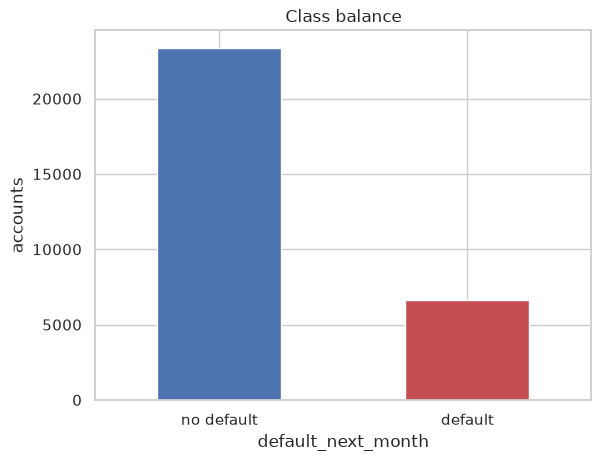

In [2]:
base = df[TARGET].mean()
print(f"default rate: {base:.4f}  ({df[TARGET].sum():,} of {len(df):,} accounts)")
print(f"a model that always predicts 'no default' is {1 - base:.2%} accurate and catches zero defaulters")

ax = df[TARGET].value_counts().sort_index().plot.bar(color=['#4c72b0', '#c44e52'], rot=0)
ax.set_xticklabels(['no default', 'default'])
ax.set_ylabel('accounts'); ax.set_title('Class balance')
plt.show()

## Column layout

Index 1 is the most recent month. `PAY_0`, `BILL_AMT1` and `PAY_AMT1` are September 2005;
index 6 is April. There is **no `PAY_1`** — the September repayment column is called `PAY_0`,
and assuming otherwise silently drops a month.

In [3]:
print('month per column index:', MONTH_OF_INDEX)
print('repayment status columns:', PAY_COLS)
print("PAY_1 present?", 'PAY_1' in df.columns)
df[['LIMIT_BAL', 'AGE'] + PAY_COLS[:2] + BILL_COLS[:2] + PAY_AMT_COLS[:2]].describe().T.round(1)

month per column index: {1: '2005-09', 2: '2005-08', 3: '2005-07', 4: '2005-06', 5: '2005-05', 6: '2005-04'}
repayment status columns: ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
PAY_1 present? False


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_0,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
BILL_AMT1,30000.0,51223.3,73635.9,-165580.0,3558.8,22381.5,67091.0,964511.0
BILL_AMT2,30000.0,49179.1,71173.8,-69777.0,2984.8,21200.0,64006.2,983931.0
PAY_AMT1,30000.0,5663.6,16563.3,0.0,1000.0,2100.0,5006.0,873552.0
PAY_AMT2,30000.0,5921.2,23040.9,0.0,833.0,2009.0,5000.0,1684259.0


## Repayment status is the strongest driver — and it is not ordinal

`PAY_0` is documented as: `-1` = paid duly, `1` = one month late, `2` = two months late, …
Codes `-2` and `0` are **not defined in the codebook at all**, and between them they cover
most of the column.

If the codes were ordered by risk, the default rate would rise monotonically with the code.
Wilson 95% intervals are shown because several codes hold only a handful of accounts, and a
point estimate alone invites reading a trend into noise.

In [4]:
r = rate_by_code(df, 'PAY_0')
display(r.round(4))

undocumented = df.PAY_0.isin([-2, 0]).mean()
print(f"codes -2 and 0 together: {undocumented:.1%} of all accounts, and neither is in the codebook")

r.assign(undocumented_share=undocumented, base_rate=base).to_csv(EXP + 'eda_pay0_rates.csv')

low = r.loc[[-2, -1, 0]]
print(f"codes -2, -1, 0 in code order: {list(low['rate'].round(4))}")
print(f"monotonically increasing? {bool(low['rate'].is_monotonic_increasing)}")
print(f"code 0 ({r.loc[0, 'rate']:.1%}) is safer than code -1 ({r.loc[-1, 'rate']:.1%}), "
      f"and code 2 ({r.loc[2, 'rate']:.1%}) is {r.loc[2, 'rate'] / r.loc[0, 'rate']:.1f}x code 0")

,n,defaults,rate,ci_lo,ci_hi,share
PAY_0,,,,,,
-2,2759,365,0.1323,0.1202,0.1454,0.0920
-1,5686,954,0.1678,0.1583,0.1777,0.1895
0,14737,1888,0.1281,0.1228,0.1336,0.4912
1,3688,1252,0.3395,0.3244,0.3549,0.1229
2,2667,1844,0.6914,0.6736,0.7087,0.0889
3,322,244,0.7578,0.7081,0.8013,0.0107
4,76,52,0.6842,0.5730,0.7777,0.0025
5,26,13,0.5000,0.3206,0.6794,0.0009
6,11,6,0.5455,0.2801,0.7873,0.0004


codes -2 and 0 together: 58.3% of all accounts, and neither is in the codebook
codes -2, -1, 0 in code order: [0.1323, 0.1678, 0.1281]
monotonically increasing? False
code 0 (12.8%) is safer than code -1 (16.8%), and code 2 (69.1%) is 5.4x code 0


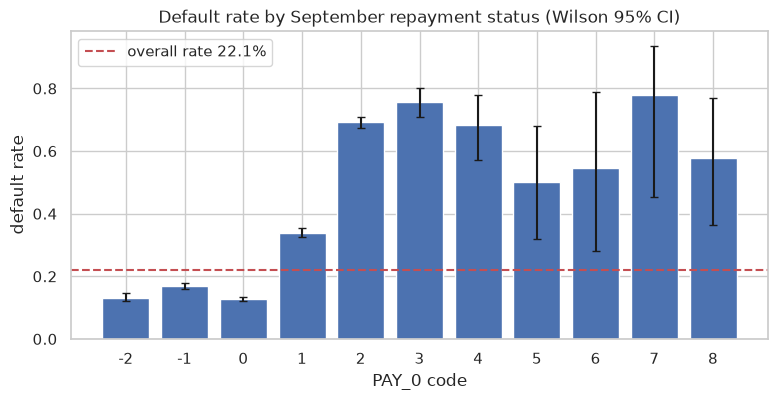

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
err = [r['rate'] - r['ci_lo'], r['ci_hi'] - r['rate']]
ax.bar(r.index.astype(str), r['rate'], yerr=err, capsize=3, color='#4c72b0')
ax.axhline(base, color='#c44e52', ls='--', label=f'overall rate {base:.1%}')
ax.set_xlabel('PAY_0 code'); ax.set_ylabel('default rate'); ax.legend()
ax.set_title('Default rate by September repayment status (Wilson 95% CI)')
plt.show()

This is the main finding. Feeding `PAY_0` to a model as an integer assumes
`-2 < -1 < 0 < 1 < 2` in risk, and the table says otherwise. Notebook 03 measures what correcting
that is worth.

## Credit limit

`LIMIT_BAL` is the bank's own prior assessment of the customer, so it should carry signal —
and it runs the right way.

In [6]:
d = df.assign(limit_decile=pd.qcut(df.LIMIT_BAL, 10, labels=False, duplicates='drop'))
by_limit = d.groupby('limit_decile').agg(n=(TARGET, 'size'),
                                         limit_from=('LIMIT_BAL', 'min'),
                                         limit_to=('LIMIT_BAL', 'max'),
                                         default_rate=(TARGET, 'mean'))
display(by_limit.round(4))
print(f"bottom decile {by_limit.default_rate.iloc[0]:.1%} vs top decile {by_limit.default_rate.iloc[-1]:.1%}")
by_limit.to_csv(EXP + 'eda_limit_deciles.csv')

,n,limit_from,limit_to,default_rate
limit_decile,,,,
0,4081,10000,30000,0.3585
1,3595,40000,50000,0.2718
2,1556,60000,70000,0.2847
3,3266,80000,100000,0.2453
4,2792,110000,140000,0.2285
5,3331,150000,180000,0.1735
6,2487,190000,210000,0.1753
7,2934,220000,270000,0.1629
8,3482,280000,360000,0.1516


bottom decile 35.8% vs top decile 11.9%


## Bills and payments

The raw amounts matter less than the relationship between them: what was owed versus what was
actually paid. A customer paying a token fraction of a large bill is in a different position
from one clearing it.

In [7]:
paid = df.PAY_AMT1 / df.BILL_AMT1.where(df.BILL_AMT1 > 0)
band = pd.cut(paid, [-0.01, 0.001, 0.05, 0.2, 0.5, 0.999, np.inf],
              labels=['paid nothing', '<5%', '5-20%', '20-50%', '50-99%', 'cleared it'])
by_paid = df.assign(band=band).groupby('band', observed=True).agg(
    n=(TARGET, 'size'), default_rate=(TARGET, 'mean'))
display(by_paid.round(4))
print(f"{by_paid.default_rate.max():.1%} for the worst band vs {by_paid.default_rate.min():.1%} for the best")
by_paid.to_csv(EXP + 'eda_payment_ratio.csv')

,n,default_rate
band,,
paid nothing,3630,0.3956
<5%,8094,0.1919
5-20%,7954,0.2220
20-50%,2301,0.1873
50-99%,1548,0.1331
cleared it,3875,0.1551


39.6% for the worst band vs 13.3% for the best


In [8]:
corr = df[['LIMIT_BAL', 'AGE'] + PAY_COLS + BILL_COLS + PAY_AMT_COLS + [TARGET]].corr()[TARGET]
print('Pearson correlation with the target (linear association only):')
display(corr.drop(TARGET).sort_values(key=abs, ascending=False).head(10).round(4).to_frame('corr'))

Pearson correlation with the target (linear association only):


,corr
PAY_0,0.3248
PAY_2,0.2636
PAY_3,0.2353
PAY_4,0.2166
PAY_5,0.2041
PAY_6,0.1869
LIMIT_BAL,-0.1535
PAY_AMT1,-0.0729
PAY_AMT2,-0.0586
PAY_AMT4,-0.0568


## Demographics

Weak, and included here mainly to show how weak. `SEX` is dropped from the final model
regardless: sex cannot lawfully enter a credit decision in most jurisdictions.

In [9]:
for col in ['SEX', 'EDUCATION', 'MARRIAGE']:
    t = rate_by_code(df, col)[['n', 'rate', 'ci_lo', 'ci_hi']]
    print(f"--- {col} ---"); display(t.round(4))
    print(f"spread between the largest groups: "
          f"{t[t.n > 1000].rate.max() - t[t.n > 1000].rate.min():.3f}\n")

--- SEX ---


,n,rate,ci_lo,ci_hi
SEX,,,,
1,11888,0.2417,0.2341,0.2495
2,18112,0.2078,0.2019,0.2137


spread between the largest groups: 0.034

--- EDUCATION ---


,n,rate,ci_lo,ci_hi
EDUCATION,,,,
0,14,0.0000,0.0000,0.2153
1,10585,0.1923,0.1850,0.2000
2,14030,0.2373,0.2304,0.2445
3,4917,0.2516,0.2396,0.2639
4,123,0.0569,0.0278,0.1128
5,280,0.0643,0.0410,0.0993
6,51,0.1569,0.0817,0.2801


spread between the largest groups: 0.059

--- MARRIAGE ---


,n,rate,ci_lo,ci_hi
MARRIAGE,,,,
0,54,0.0926,0.0402,0.1991
1,13659,0.2347,0.2277,0.2419
2,15964,0.2093,0.2030,0.2157
3,323,0.2601,0.2152,0.3105


spread between the largest groups: 0.025



### What to carry forward

1. The base rate sets the floor for every metric. Accuracy is unusable on its own.
2. Repayment status dominates, and its codes are categories, not a scale.
3. Credit limit and the size of the last payment carry real signal.
4. Demographics are weak; `SEX` is excluded on legal grounds, not statistical ones.